## TESTING DATA

In [55]:
import pandas as pd
import numpy as np

data_file_path_test = "./data/mnist/mnist_test.csv"

df_test = pd.read_csv(data_file_path_test)

df_test.head(5)

,7,0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,...,0.658,0.659,0.660,0.661,0.662,0.663,0.664,0.665,0.666,0.667
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [56]:
df_test.min()

7        0
0        0
0.1      0
0.2      0
0.3      0
        ..
0.663    0
0.664    0
0.665    0
0.666    0
0.667    0
Length: 785, dtype: int64

In [57]:
df_test.max()

7        9
0        0
0.1      0
0.2      0
0.3      0
        ..
0.663    0
0.664    0
0.665    0
0.666    0
0.667    0
Length: 785, dtype: int64

In [58]:
df_test.describe()

,7,0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,...,0.658,0.659,0.660,0.661,0.662,0.663,0.664,0.665,0.666,0.667
count,9999.000000,9999.0,9999.0,9999.0,9999.0,9999.0,9999.0,9999.0,9999.0,9999.0,...,9999.000000,9999.000000,9999.000000,9999.000000,9999.0,9999.0,9999.0,9999.0,9999.0,9999.0
mean,4.443144,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.179318,0.163616,0.052605,0.000600,0.0,0.0,0.0,0.0,0.0,0.0
std,2.895897,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,5.674433,5.736359,2.420125,0.060003,0.0,0.0,0.0,0.0,0.0,0.0
min,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
25%,2.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
50%,4.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
75%,7.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
max,9.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,253.000000,253.000000,156.000000,6.000000,0.0,0.0,0.0,0.0,0.0,0.0


In [59]:
Y_test = df_test.iloc[0:, 0:1]
x_test = df_test.iloc[0:, 1:]

x_test = x_test.to_numpy()
Y_test = Y_test.to_numpy()
print(x_test.shape, Y_test.shape)

(9999, 784) (9999, 1)


In [60]:
x_test = x_test.reshape(9999, 1, 28, 28)

nb_classes = 10
one_hot_targets_test = np.eye(nb_classes)[Y_test]
one_hot_targets_test = one_hot_targets_test.reshape(one_hot_targets_test.shape[0], -1)

One Hot [0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
Label 7


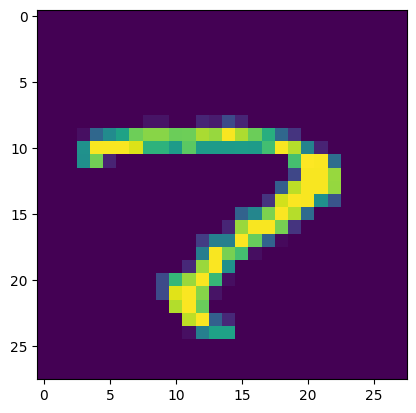

In [61]:
from matplotlib import pyplot as plt

random_choice = np.random.randint(0, 9999)
print(f"One Hot {one_hot_targets_test[random_choice]}")
print(f"Label {np.argmax(one_hot_targets_test[random_choice])}")
plt.imshow(x_test[random_choice][0])
plt.show()

## DATA GROUPING

In [62]:
import pandas as pd
import numpy as np

data_file_path_test = "./data/mnist/mnist_test.csv"

df_test = pd.read_csv(data_file_path_test)

Y_test = df_test.iloc[:, 0].to_numpy()
x_test = df_test.iloc[:, 1:].to_numpy()

print(x_test.shape, Y_test.shape)

(9999, 784) (9999,)


In [63]:
x_test_grouped = []
Y_test_grouped = []

for label in range(10):
    indices = np.where(Y_test == label)[0][:100]

    x_test_grouped.append(x_test[indices])
    Y_test_grouped.append(Y_test[indices])

x_test_grouped = np.concatenate(x_test_grouped, axis=0)
Y_test_grouped = np.concatenate(Y_test_grouped, axis=0)

print(x_test_grouped.shape)
print(Y_test_grouped.shape)

(1000, 784)
(1000,)


## QUANTITIZE DATA INTO INT8

In [64]:
import os
import numpy as np

def generate_mem_files(pixel_data, label, file_index):
    
    flat_data = pixel_data.reshape(-1)

    folder_path = f"./image-hex-gen-test/mnist_img_{label}"
    os.makedirs(folder_path, exist_ok=True)

    file_path = f"{folder_path}/img_label_{label}_{file_index}.mem"
    
    with open(file_path, "w") as f:
        for pixel in flat_data:
            val = int(np.clip(pixel, 0, 255))
            f.write(f"{val:02X}\n")

In [65]:
for label in range(10):
    start = label * 100
    end = start + 100

    for file_index, i in enumerate(range(start, end)):
        generate_mem_files(
            x_test_grouped[i],
            Y_test_grouped[i],
            file_index
        )

In [66]:
import numpy as np

def convert_to_mem_file(frames_data, frame_num, fname):
    with open(fname, "w") as f:
        for i in range(frame_num):
            frame = frames_data[i].reshape(-1)

            for pixel in frame:
                val = int(np.clip(pixel, 0, 255))
                f.write(f"{val:02X}\n")

In [67]:
convert_to_mem_file(
    x_test_grouped,
    len(x_test_grouped),
    "./image-hex-gen-test/img_test.mem"
)